In [73]:
import numpy as np
import matplotlib.pyplot as plt
import json

from os.path import exists
from tqdm import tqdm
from subprocess import check_output
from shapely import union, Polygon, buffer, get_coordinates
from scipy.interpolate import interp1d
from stl import mesh
from polylabel import polylabel
from sklearn.metrics import pairwise_distances

In [74]:
faux_monnayeurs = mesh.Mesh.from_file("../temp/surface_cleaned_faux_monnayeur.stl")

In [75]:
np.median(np.linalg.norm(faux_monnayeurs.vectors - np.roll(faux_monnayeurs.vectors, -1, axis=1), axis = 2).flatten())*7.21

0.3712398479878902

In [76]:
closed_trumpet = mesh.Mesh.from_file("../temp/Trumpet_closed_v2.stl")

In [77]:
np.median(np.linalg.norm(closed_trumpet.vectors - np.roll(closed_trumpet.vectors, -1, axis=1), axis = 2).flatten())*1000

0.6529759848490357

In [78]:
ntriangles = faux_monnayeurs.vectors.shape[0]
triangle_vertices = faux_monnayeurs.vectors.reshape((ntriangles*3, 3))
unique_vertices = np.unique(triangle_vertices, axis=1)

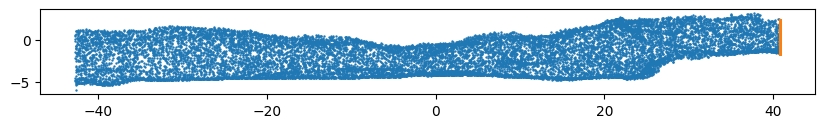

In [79]:
fig, ax = plt.subplots(figsize = (10,10))

ax.scatter(*unique_vertices[::500, [0,1]].T, s=0.5)
inlet = unique_vertices[np.abs(unique_vertices[:, 0] - np.max(unique_vertices[:, 0])) < 0.0015]
ax.scatter(*inlet[:, [0,1]].T, s = 0.5)
ax.set_aspect("equal")
plt.show()

In [80]:
inlet.shape

(2521, 3)

## ordering the section. 

In [ ]:
from scipy.sparse.csgraph import minimum_spanning_tree
import networkx as nx
from sklearn.metrics import pairwise_distances

In [ ]:
pwdist = pairwise_distances(inlet[:, [1, 2]])
thetree = minimum_spanning_tree(pwdist)
G = nx.Graph(thetree)

# find the longest path in a tree using two successive bfs searches. 
bfs_1 = nx.bfs_tree(G, 0)
first_endpoint = list(bfs_1.edges())[-1][-1]

bfs_2 = nx.bfs_tree(G, first_endpoint)
second_endpoint = list(bfs_2.edges())[-1][-1]

thepath = nx.shortest_path(G, first_endpoint, second_endpoint)
inlet_ordered = inlet[thepath]

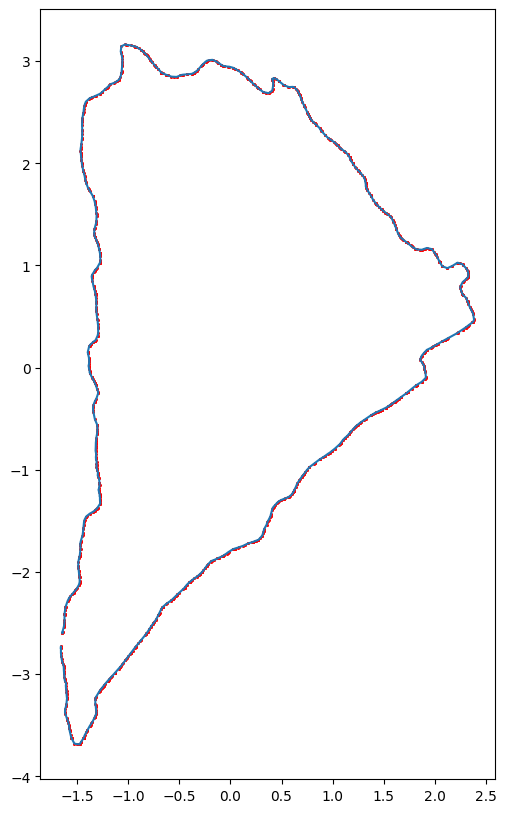

In [118]:
fig, ax  = plt.subplots(figsize = (10,10))
ax.scatter(*inlet[:, [1, 2]].T, color = "r", s = 1)
ax.plot(*inlet[thepath][:, [1, 2]].T, "-")
ax.set_aspect("equal")

## Designing a connector smoothly transitioning from a cross-section to the next

In [119]:
# scaling ratio model to reality
scale_ratio = 7.21 

In [ ]:
# shape A. 
a = inlet[thepath][:, [2, 1]] * scale_ratio

# rescale and recenter the profile
a = a - polylabel([a])

# dn25 inner radius 
thetai = np.linspace(-np.pi, np.pi, len(a))
b = np.array([53.6/2*np.cos(thetai), 53.6/2*np.sin(thetai)]).T


In [ ]:
# how much to resample by
target_resample_step = 0.37

perimeter_dn25 = np.pi*53.6


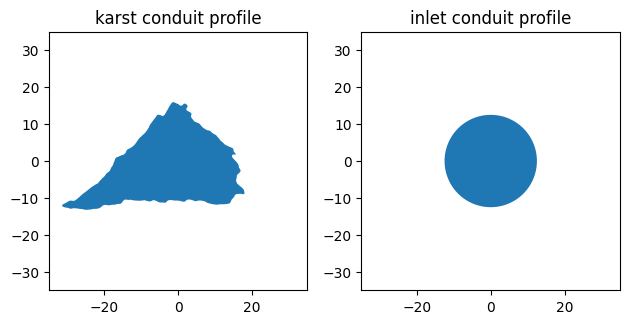

In [133]:
fig, axes = plt.subplots(1, 2)

axes[0].fill(*a.T)
axes[0].set_title("karst conduit profile")
axes[1].fill(*b.T)
axes[1].set_title("inlet conduit profile")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlim(-35, 35)
    ax.set_ylim(-35, 35)

plt.tight_layout()
plt.savefig("../temp/the_two_shapes.png", dpi = 300)
plt.show()

## Make a wrapper for the fernandez-polygon-decomposition algorithm written in Javascript

In [134]:
header = """const { decompose } = require('fernandez-polygon-decomposition');
const { orderClockwise } = require('fernandez-polygon-decomposition');

"""
footer = """
const goodPolygon = orderClockwise(polygon);
const convexPartition = decompose(goodPolygon);

console.log(convexPartition);

const FileSystem = require("fs");
 FileSystem.writeFile('temp.json', JSON.stringify(convexPartition), (error) => {
    if (error) throw error;
  });"""

In [135]:
def decompose(polygon):
    """This function wraps the javascript library fernandez-polygon-decomposition
    using subprocess. The decomposition is based on the following paper: 
    https://doi.org/10.1016/S0377-2217(99)00033-8

    :param polygon: an array of polygon coordinates given in consecutive order. They are
    automatically flipped into the correct clockwise enumeration in this wrapper.
    :type polygon: _type_
    :return: list of convex polygons as a partition
    :rtype: list(np.ndarray)
    """
    # write a js file. 

    with open("polygon.js", "w") as f:
        f.write(header)
        f.write("const polygon = [")

        f.write(f"{{x: {polygon[0,0]}, y:{polygon[0,1]}}},\n")
        for elem in polygon[1:-1]:
            f.write(f"\t\t{{x: {elem[0]}, y:{elem[1]}}},\n")
        f.write(f"\t\t{{x: {polygon[-1,0]}, y:{polygon[-1,1]}}},\n")
        f.write("];\n\n")
        f.write(footer)
        f.close()

    # run the polygon partition algorithm
    _ = check_output("node polygon.js")

    with open("temp.json" , "r") as f:
        y = json.load(f)
        f.close()

    #_ = check_output("del ../polygon.js")
    #_ = check_output("del ../temp.json")

    convex_poly = []
    for triangle in y:
        triangle_array = np.zeros((len(triangle), 2))
        for c, vertex in enumerate(triangle):
            triangle_array[c] = [vertex["x"], vertex["y"]]
        
        convex_poly.append(triangle_array)

    return convex_poly
        

In [136]:
simple_polygon = np.array([[2.12, 0.45],[2.34, 1.5],[2.78,0.98],[3.23,2.45], [2.77, 3.4],[2.45, 3.34],[2.51, 2.24],[2.09, 1.42]])
convex_partition = decompose(simple_polygon)

# compute the convex partition for a simple, non convex polygon.

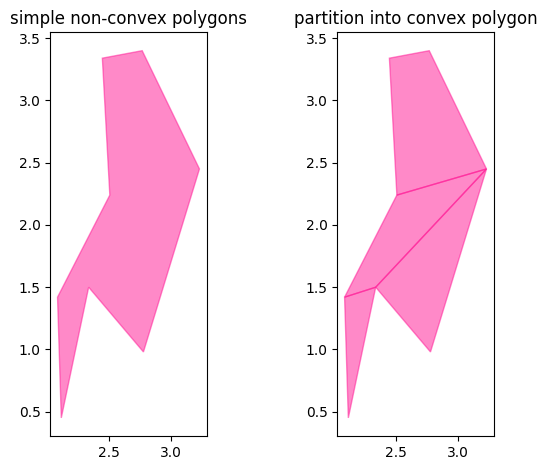

In [137]:
fig, axes = plt.subplots(1, 2)

ax = axes[0]
ax.fill(*simple_polygon.T, alpha = 0.5, color = "deeppink")
ax.set_aspect("equal")
ax.set_title("simple non-convex polygons")


ax = axes[1]
for convex in convex_partition:
    ax.fill(*convex.T, alpha = 0.5, color = "deeppink")

ax.set_aspect("equal")
ax.set_title("partition into convex polygon")
plt.tight_layout()
plt.savefig("../temp/partition_into_polygons.png", dpi = 300)

plt.show()

In [138]:
convex_partition = decompose(a)


fig, axes = plt.subplots(1, 2)

ax = axes[0]
ax.fill(*a.T, alpha = 0.5, color = "deeppink")
ax.set_aspect("equal")
ax.set_title("simple non-convex polygon")


ax = axes[1]
for convex in convex_partition:
    ax.fill(*convex.T, alpha = 0.5, color = "deeppink", lw = 0.5)

ax.set_aspect("equal")
ax.set_title("partition into convex polygons")
plt.tight_layout()
plt.savefig("../temp/partition_into_polygons_real.png", dpi = 300)

plt.show()

CalledProcessError: Command 'node polygon.js' returned non-zero exit status 1.

In [19]:
# compute the minkovski sm

def slope_line(p1,p2): #takes in two points and finds the slope of line joining them
    m = p2-p1
    if np.arctan2(m[1],m[0]) >= 0:
        return np.arctan2(m[1],m[0])
    else:
        return 2*np.pi + np.arctan2(m[1],m[0])
    
# minkovski sum is easy if both are convex. 
def minkovski_sum(a, b, wa):

    i = 0 
    j = 0
    wb = 1-wa
    minkowski_sum_vertices = []  # Collecting vertices of the minkowski sum
        

    # we need to start from the two bottommost vertices. 
    mina = np.argmin(a[:, 1])
    minb = np.argmin(b[:, 1])

    a_roll = np.roll(a, -mina, axis=0)
    b_roll = np.roll(b, -minb, axis=0)

    a_closed = np.vstack([a_roll, a_roll[0]])
    b_closed = np.vstack([b_roll, b_roll[0]])

    minkowski_sum_vertices.append(wa*a_closed[i]+wb*b_closed[j])

    while not((i==len(a_closed)-1) and (j==len(b_closed)-1))  :
        if i == len(a_closed)-1:
                j = j+1
        elif j == len(b_closed)-1:
                i = i+1
        elif slope_line(a_closed[i],a_closed[i+1]) < slope_line(b_closed[j],b_closed[j+1]) : #selecting the next vertex depending on angle transition
                i = i+1
        elif slope_line(a_closed[i],a_closed[i+1]) > slope_line(b_closed[j],b_closed[j+1]): #selecting the next vertex depending on angle transition
                j = j+1
        else:
                i = i+1
                j = j+1
        
        minkowski_sum_vertices.append(wa*a_closed[i]+wb*b_closed[j])
            
    return np.array(minkowski_sum_vertices)

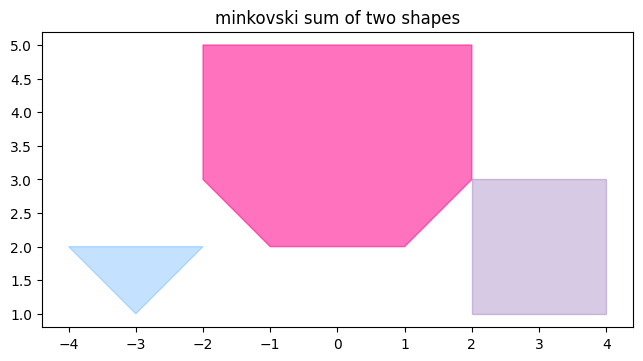

In [20]:
# test the commutativity of the minkovski sum on simple polygons. 

triangle = np.array([[-4, 2],[-3, 1],[-2, 2]])
square = np.array([[2,1],[4,1],[4,3],[2,3]])
diamond = np.array([[-0.5, -0.5],[-0.25, 0],[-0.5, 0.5],[-0.75, 0]])

simple_convex_polygon = np.array([[2.12, 0.45],[2.78,0.98],[3.23,2.45],[2.45, 3.34],[2.21, 2.24],[2.09, 1.42]])


fig, ax = plt.subplots()

ax.fill(*triangle.T,color = "dodgerblue", alpha = 0.26)
ax.fill(*square.T,color = "rebeccapurple", alpha = 0.26)

mk_sum = minkovski_sum(2*triangle, 2*square, wa=0.5)
ax.fill(*mk_sum.T,color = "deeppink", alpha = 0.6)


ax.set_aspect("equal")
ax.set_title("minkovski sum of two shapes")

plt.tight_layout()
plt.savefig("../temp/simple_minkovski_sum.png", dpi = 300)
plt.show()

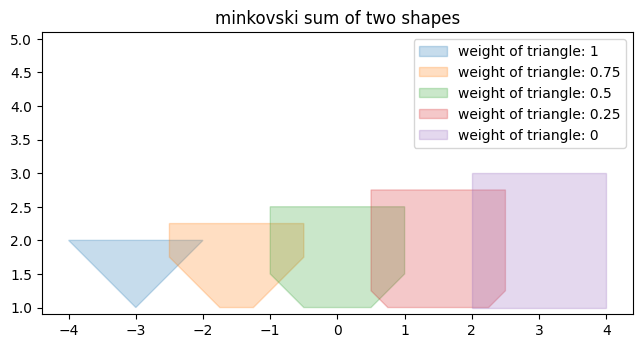

In [21]:
fig, ax = plt.subplots()


for c, w in enumerate((0, 0.25, 0.5, 0.75, 1)):
    mk_sum = minkovski_sum(square, triangle, wa=w)
    ax.fill(*mk_sum.T,color = f"C{c}", alpha = 0.25, label = f"weight of triangle: {1-w}")


ax.set_ylim(0.9,5.1)
ax.set_aspect("equal")
ax.legend()
ax.set_title("minkovski sum of two shapes")

plt.tight_layout()
plt.savefig("../temp/simple_minkovski_sum_weighted.png", dpi = 300)
plt.show()

In [22]:
def get_full_minkovski_sum(a,b, w):
    """Given a and b two sets of convex polygon partitions of any shape, compute
    the full minkowski sum of the two partitions.

    See https://doc.cgal.org/latest/Minkowski_sum_2/index.html for details.

    :param a: a convex polygon partition
    :type a: list(array)
    :param b: another convex polygon partition
    :type b: list(array)
    :param w: the weight for the sum.
    :type w: float
    :return: a polygon reprenting the minkowski sum of the two convex polygon partitions
    :rtype: array
    """
    
    sums = []
    previous = Polygon([[0,0],[0,0],[0,0]])


    for i in range(len(a)):
        for j in range(len(b)):
            # the minkovski sum assumes cyclical polygons closed.
            new = Polygon(minkovski_sum(a[i], b[j],  wa = w))
            sums.append(buffer(new, 0.001))
            previous = union(previous, buffer(new, 0.001))

    # important: enlever les trous. 
    mk_full_sum = get_coordinates(previous.exterior)

    return mk_full_sum

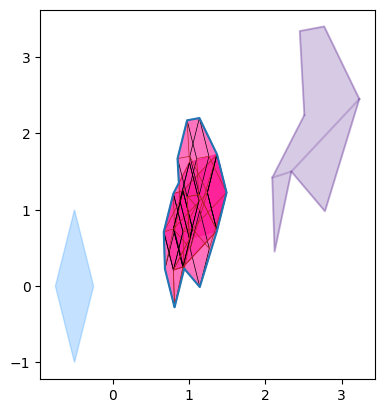

In [23]:
# test the commutativity of the minkovski sum on simple polygons. 
diamond = np.array([[-0.5, -1],[-0.25, 0],[-0.5, 1],[-0.75, 0]])
diamond_closed = np.array([[-0.5, -1],[-0.25, 0],[-0.5, 1],[-0.75, 0], [-0.5, -1]])


fig, ax = plt.subplots()

ax.fill(*diamond.T,color = "dodgerblue", alpha = 0.26)

ax.fill(*simple_polygon.T,color = "rebeccapurple", alpha = 0.26)

for convex in decompose(simple_polygon):
      ax.plot(*convex.T,color = "rebeccapurple", alpha = 0.26)

      mk_sum = minkovski_sum( convex, diamond,wa=0.5)
      ax.fill(*mk_sum.T,color = "deeppink", alpha = 0.6)
      
      for vertex in convex:
            ax.plot(*(0.5*diamond_closed+0.5*vertex).T, color ="k", lw = 0.5)

      for vertex in diamond_closed:
            ax.plot(*(0.5*convex+0.5*vertex).T, color ="firebrick", lw = 0.5)

ax.plot(*get_full_minkovski_sum(decompose(simple_polygon), [diamond], w = 0.5).T )
ax.set_aspect("equal")



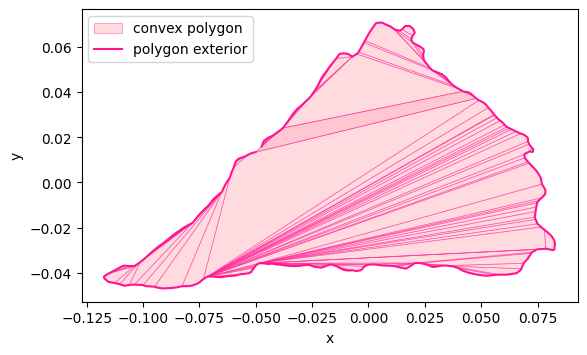

In [24]:
convex_polygons_a = decompose(a)

fig, ax = plt.subplots()

for segment in convex_polygons_a:
    ax.fill(*segment.T, color = "lightpink", edgecolor = "deeppink", alpha = 0.5, lw = 0.5)

ax.fill(*convex_polygons_a[-1].T, color = "lightpink", edgecolor = "deeppink", alpha = 0.5, lw = 0.5, label = "convex polygon")
#ax.fill(*a.T, color = "deeppink", alpha = 0.5)
ax.plot(*a.T, label = "polygon exterior", color = "deeppink")
ax.set_aspect("equal")
ax.legend()

ax.set_xlabel("x")
ax.set_ylabel("y")

plt.savefig("../temp/Profile_convex_decomposition.png", dpi = 300)
plt.show()

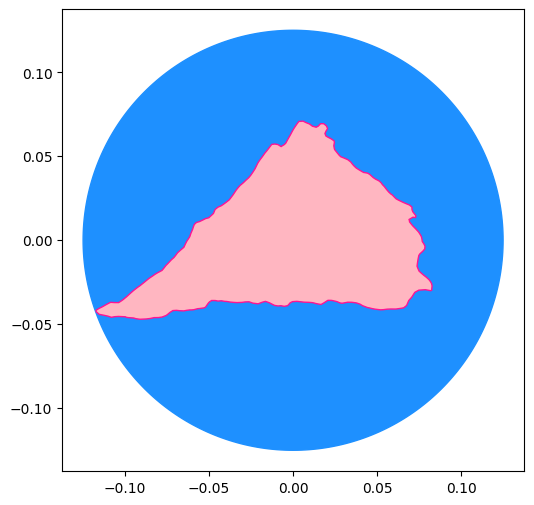

In [25]:
thetai = np.linspace(-np.pi, np.pi, len(a))

fig, ax = plt.subplots(figsize = (6, 6))
ax.fill(*b.T, color = "dodgerblue", zorder =-100)

ax.fill(*a.T, color = "lightpink", edgecolor="deeppink")
ax.set_aspect("equal")
plt.savefig("../temp/trumpet_inlet_outlet.png", dpi =300)

## Smoother transition between the different shape weights

In [26]:
def polynomial(x, Hi, He):
    return Hi - (Hi-He)* (6*x**5 - 15*x**4+10*x**3)

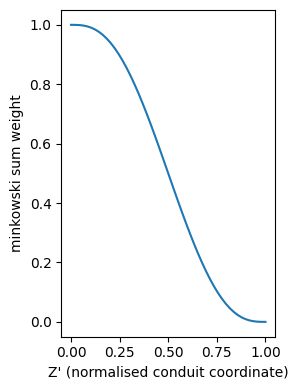

In [27]:
xi = np.linspace(0, 1)
wi = polynomial(xi, 1, 0)

fig, ax = plt.subplots(figsize = (3, 4))
ax.plot(xi, wi)
ax.set_xlabel("Z' (normalised conduit coordinate)")
ax.set_ylabel("minkowski sum weight")
plt.tight_layout()
plt.savefig("../temp/minkowski_sum_weight_polynomial.png", dpi = 300)
plt.show()

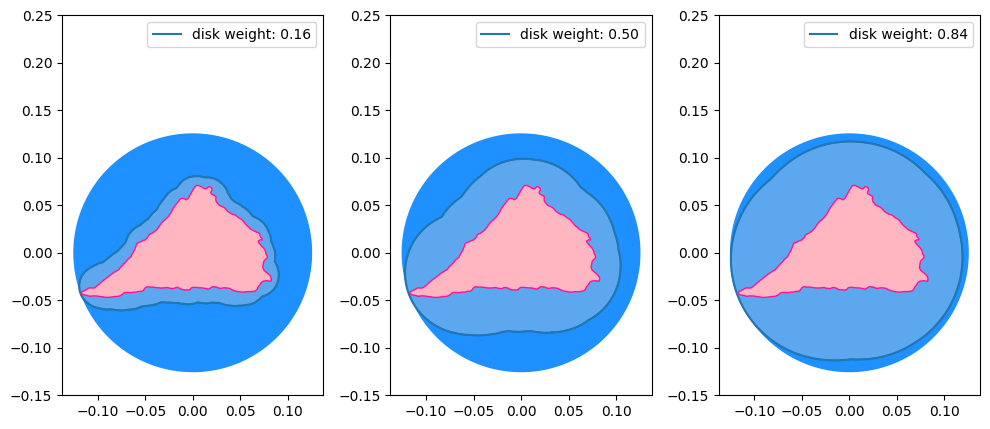

In [28]:
thetai = np.linspace(-np.pi, np.pi, len(a))

wi = ( 0.3, 0.5, 0.7)

fig, axes = plt.subplots(1, len(wi), figsize = (10, 5))

for w,ax in zip(wi, axes.flatten()):
    
    wnorm = polynomial(w, 1, 0)
    subsample = np.floor(2 / (1-wnorm)).astype(int)
    mk_sum = get_full_minkovski_sum(convex_polygons_a, [b[::subsample]], wnorm)

    ax.fill(*mk_sum.T, color = "lightgrey", edgecolor="k", alpha = 0.35)
    ax.plot(*mk_sum.T, label=f"disk weight: {1-wnorm:.2f}")
    ax.fill(*b.T, color = "dodgerblue", zorder = -100)


    ax.fill(*a.T, color = "lightpink", edgecolor="deeppink", zorder = 100)
    ax.set_aspect("equal")
    ax.set_ylim(-0.15, 0.25)
    ax.legend()

plt.tight_layout()
plt.savefig("../temp/trumpet_inlet_outlet_with_intermediate_forms.png", dpi =300)
plt.show()

In [29]:
# now we resample the polyline with an equal number of points 

def resample(a, nt= 501):
    cum_length = np.hstack([[0],np.cumsum(np.linalg.norm(np.diff(a, axis=0), axis =1)).flatten()])

    fx = interp1d(cum_length, a[:, 0], kind = "linear")
    fy = interp1d(cum_length, a[:, 1], kind = "linear")

    return np.array([fx(np.linspace(0, cum_length[-1],nt)), fy(np.linspace(0, cum_length[-1],nt))]).T

In [30]:
total_it = 1000 # change to 1000 for dense point cloud? 
nt = 1001
vertices = np.zeros((nt*total_it, 3))
zi = np.linspace(0,0.5, total_it)
keep = False

if keep == True and exists("mesh_vertices.txt"):
    mesh_vertices = np.loadtxt("mesh_vertices.txt")

else: 

    for c, x in tqdm(enumerate(np.linspace(0,1,total_it)), total=total_it):
        w = polynomial(x, 1,0)

        convex_X  = decompose(a[::4])
        subsample = np.floor(2 / (1-wnorm)).astype(int)
        profile = get_full_minkovski_sum(convex_X, [b[::subsample]], w)

        resampled_profile = resample(profile, nt=nt)
        
        minY = np.argmin(resampled_profile[:, 1])

        resampled_profile = np.roll(resampled_profile, - minY, axis =0)
        
        vertices[c*nt:(c+1)*nt] = np.vstack([resampled_profile.T, np.ones(len(resampled_profile))*zi[c]]).T
        
        # save them to text.
        np.savetxt("mesh_vertices.txt", vertices)

100%|██████████| 1000/1000 [1:15:57<00:00,  4.56s/it]


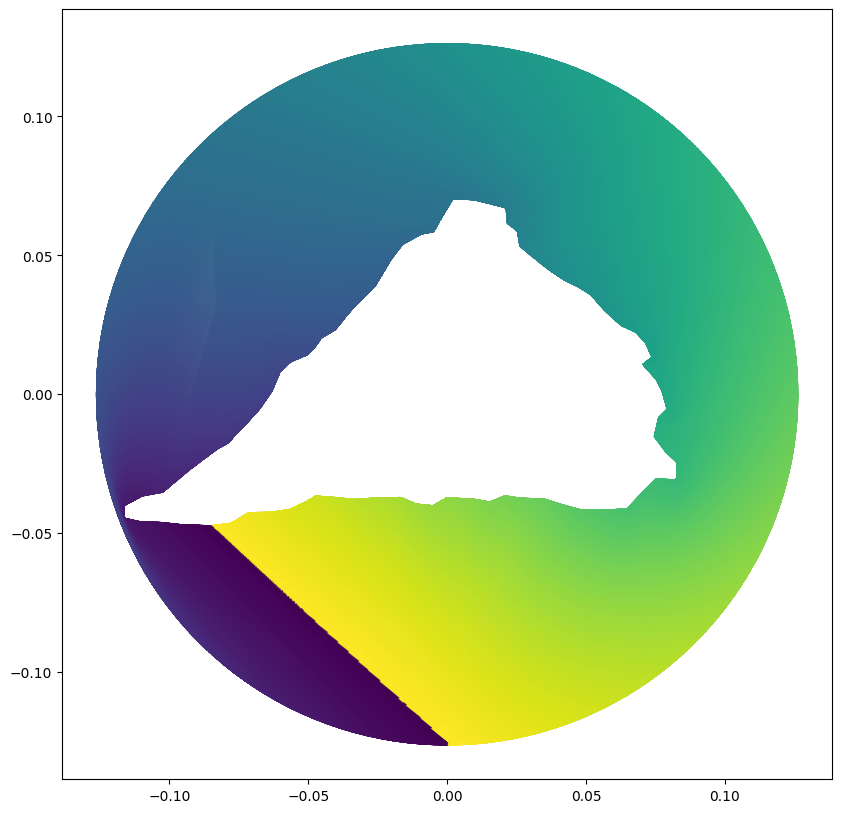

In [31]:
fig, ax = plt.subplots(figsize = (10,10))

for c in range(total_it):
    ax.scatter(*vertices[c*nt:(c+1)*nt, [0,1]].T, c= np.arange(0,nt), s=0.5, alpha = 0.5)

ax.set_aspect("equal")
plt.show()

## Meshing this point cloud
At this point, we mesh each strip corresponding to a profile

In [32]:
# for each row: 
nti = np.arange(0, nt).astype(int)
vertices_index = np.arange(total_it*nt).astype(int)

strips = []

# build the triangulated mesh.

for c in range(total_it-1):
    triangular_faces_1st = np.array([vertices_index[c*nt:(c+1)*nt-1], 
                                     vertices_index[(c+1)*nt:(c+2)*nt-1], 
                                     vertices_index[(c+1)*nt+1:(c+2)*nt]]).T
    
    last_1st = np.array([vertices_index[(c+1)*nt-1], 
                         vertices_index[(c+2)*nt-2], 
                         vertices_index[(c+1)*nt]]).T

    triangular_faces_2nd = np.array([vertices_index[c*nt:(c+1)*nt-1], 
                                     vertices_index[(c+1)*nt+1:(c+2)*nt], 
                                      vertices_index[c*nt+1:(c+1)*nt]]).T

    last_2nd = np.array([vertices_index[(c+1)*nt-1], 
                         vertices_index[(c+1)*nt], 
                         vertices_index[c*nt]]).T

    strips.append(np.vstack([triangular_faces_1st,last_1st, triangular_faces_2nd, last_2nd]))

faces = np.vstack(strips)


In [33]:
inlet_face = vertices_index[-nt:]
outlet_face = vertices_index[:nt]

# inlet is a disk, so, we should be able to write new triangles easily. 
inlet_face_triangles = []
inlet_origin = np.mean(vertices[inlet_face], axis = 0)

for vertex_index1, vertex_index2 in zip(inlet_face, np.roll(inlet_face, 1)):
    vector = np.array([inlet_origin, vertices[vertex_index1], vertices[vertex_index2]])
    inlet_face_triangles.append(vector)

In [34]:
decomposed = decompose(vertices[outlet_face][:, [0,1]])

In [35]:

outlet_face_triangles = []

for convex in decomposed:
    indices = []

    cog = np.zeros(3)
    cog[[0,1]] = np.mean(convex, axis =0)


    for vertex in convex:
        idx = np.argmin(np.linalg.norm(vertices[:, [0,1]]-vertex, axis =1))
        indices.append(idx)

    convex_indices = np.array(indices)

    for vertex_index1, vertex_index2 in zip(convex_indices, np.roll(convex_indices, 1)):
        outlet_face_triangles.append(np.array([cog, 
                                               vertices[vertex_index1], 
                                               vertices[vertex_index2]]))

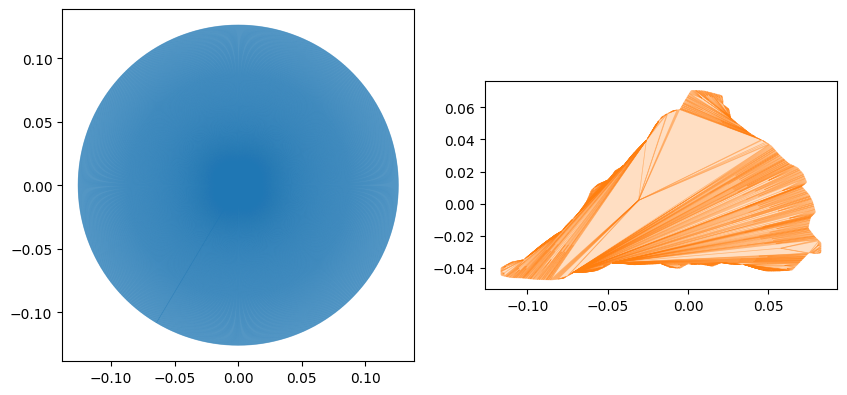

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10,10))

ax= axes[0]

for triangle in inlet_face_triangles:
    ax.fill(*triangle[:, [0,1]].T, color = "C0", alpha = 0.5, lw = 0.5)

ax.set_aspect("equal")

ax= axes[1]

for triangle in outlet_face_triangles:
    ax.fill(*triangle[:, [0,1]].T, color = "C1", alpha = 0.25, lw = 0.5)

ax.set_aspect("equal")

plt.show()

In [37]:
# Create the mesh

surface_faces_count = faces.shape[0]
inlet_faces_count = nt
outlet_faces_count = len(outlet_face_triangles)
total_faces_count = surface_faces_count + inlet_faces_count + outlet_faces_count

surface = mesh.Mesh(np.zeros(total_faces_count, dtype=mesh.Mesh.dtype))


for i, f in enumerate(faces):
    for j in range(3):
        surface.vectors[i][j] = vertices[f[j],:]

for i, f in enumerate(inlet_face_triangles):
    surface.vectors[surface_faces_count+i] = f

for i, f in enumerate(outlet_face_triangles):
    surface.vectors[surface_faces_count+inlet_faces_count+i] = f

In [38]:
surface.save("../temp/Trumpet_closed_v2.stl")

In [ ]:
def longest_extent(profile):
    pwdist = pairwise_distances(profile[:, [1,2]])
    argmax_rows = np.argmax(pwdist, axis = 1)
    max_rows = np.max(pwdist, axis = 1)


    argmax_col = np.argmax(max_rows)
    argmax_row = argmax_rows[argmax_col]

    return argmax_col, argmax_row, pwdist[argmax_row, argmax_col]

In [ ]:
max_row, max_col, max_pwdst = longest_extent(inlet)

In [ ]:
fig, ax = plt.subplots()

ax.scatter(*inlet[:, [2,1]].T)
ax.plot(*inlet[[max_col, max_row]][:, [2,1]].T)
ax.set_aspect("equal")

In [ ]:
a = np.loadtxt("../temp/Faux-Monnayeurs-inlet_2D.txt")
pwdist_real = pairwise_distances(a[:, [0,1]])
argmax_rows = np.argmax(pwdist_real, axis = 1)
max_rows = np.max(pwdist_real, axis = 1)


argmax_cola = np.argmax(max_rows)
argmax_rowa = argmax_rows[argmax_cola]

In [ ]:
fig, ax = plt.subplots(figsize = (10,10))

ax.scatter(*a[:, [0,1]].T, label = "original file (Tanguy cut, real coords in M)", s = 0.4)
#ax.plot(*a[[argmax_cola, argmax_rowa]][:, [0,1]].T)
ax.set_aspect("equal")

ax.scatter(*inlet[:, [2,1]].T, label = "clean stl by Ismail, no coords.", s = 0.4)
#ax.plot(*inlet[[max_col, max_row]][:, [2,1]].T, label ="longest extent")
ax.set_aspect("equal")
ax.grid()
ax.legend()
plt.savefig("../temp/comparison.png", dpi = 300)

In [ ]:
print(max_pwdst)